# 04 - Choose the decision threshold by cost

A model outputs a **probability**. The hospital needs a **yes/no**: call this patient for follow-up or not.
The threshold that turns one into the other is a *business* decision, so we choose it by money, not by accuracy.

**Inputs:** clean data, the train/test split and both models from notebook 03.
**Output:** the chosen threshold in `models/threshold.json`, used by the fairness notebook.

## The cost model (all assumptions stated)

| Symbol | Meaning | Value | Basis |
|---|---|---|---|
| `C_READMIT` | Cost of one 30-day readmission | **$15,000** | Assumption, order of magnitude of US inpatient stay costs (AHRQ HCUP briefs); verify before quoting |
| `C_FOLLOWUP` | Cost of one follow-up (nurse call + visit) per flagged patient | **$500** | Assumption |
| `EFFECT` | Share of readmissions the follow-up prevents | **18%** | Meta-analysis of 42 trials: pooled relative risk 0.82 for discharge interventions |

For one flagged patient:
- We always pay `C_FOLLOWUP`.
- If they *would* have been readmitted (a true positive), we prevent the readmission 18% of the time, saving `EFFECT x C_READMIT` on average.

So for any threshold:

$$\text{net savings} = TP \times EFFECT \times C\_READMIT \; - \; (TP + FP) \times C\_FOLLOWUP$$

Missed readmissions (FN) and correctly ignored patients (TN) cost the same as having no programme, so they drop out.
The comparison point is **"no programme" = $0 savings**.

**Theory check:** flag a patient when their expected saving beats the follow-up cost:
`p x EFFECT x C_READMIT > C_FOLLOWUP`, i.e. `p > C_FOLLOWUP / (EFFECT x C_READMIT)` = 500 / 2,700 = **0.185**.
That only works if the model's probabilities are *calibrated* (a "20%" really means 20%), which we check below.

## 1. Setup: rebuild X/y exactly as in notebook 03, load models

In [1]:
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix

PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT / "data" / "processed"
FIG = PROJECT / "reports" / "figures"
MODELS = PROJECT / "models"
SEED = 42
sns.set_theme(style="whitegrid")

C_READMIT = 15_000
C_FOLLOWUP = 500
EFFECT = 0.18

df = pd.read_csv(PROCESSED / "diabetic_clean.csv", dtype={"encounter_id": str, "patient_nbr": str})
split = pd.read_csv(PROCESSED / "split.csv", dtype={"encounter_id": str})
df = df.merge(split, on="encounter_id", validate="one_to_one")

X = df.drop(columns=["encounter_id", "patient_nbr", "readmit_30", "age", "set"])
y = df["readmit_30"]
is_train = df["set"] == "train"
X_train, y_train, g_train = X[is_train], y[is_train], df.loc[is_train, "patient_nbr"]
X_test, y_test = X[~is_train], y[~is_train]

models = {"Logistic regression": joblib.load(MODELS / "logreg.joblib"),
          "Gradient boosting": joblib.load(MODELS / "hgb.joblib")}
print(f"Train {len(X_train):,}  Test {len(X_test):,}")

Train 79,472  Test 19,868


## 2. Out-of-fold predictions on the training set
We must **not** choose the threshold on the test set (that would be tuning on the exam answers).
Instead, `cross_val_predict` gives every training row a prediction from a model that **did not see that row** (or that patient,
because the folds are grouped). We tune the threshold on these out-of-fold (OOF) predictions.

`clone()` copies a model's settings without its fitted weights, so each fold trains from scratch with identical settings.

In [2]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

oof = {}
test_pred = {}
for name, model in models.items():
    oof[name] = cross_val_predict(clone(model), X_train, y_train, groups=g_train,
                                  cv=cv, method="predict_proba")[:, 1]
    test_pred[name] = model.predict_proba(X_test)[:, 1]
    print(f"{name}: OOF mean prob {oof[name].mean():.3f}  (actual train rate {y_train.mean():.3f})")

Logistic regression: OOF mean prob 0.114  (actual train rate 0.114)
Gradient boosting: OOF mean prob 0.114  (actual train rate 0.114)


## 3. Are the probabilities calibrated?
Group patients into 10 bins by predicted probability, then compare the average prediction with the actual readmission rate in each bin.
Points on the diagonal = calibrated.

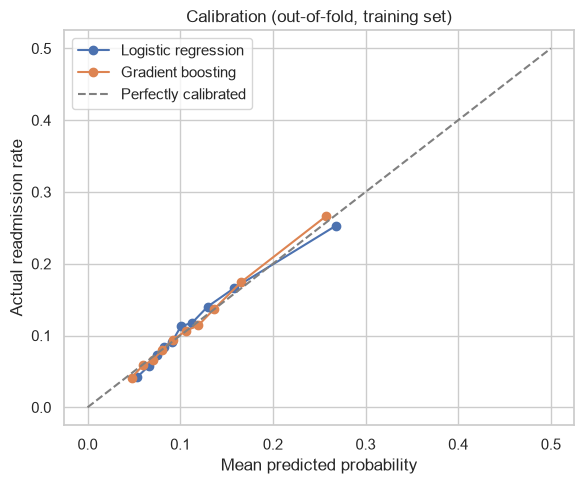

In [3]:
fig, ax = plt.subplots(figsize=(6, 5))
for name, p in oof.items():
    frac_pos, mean_pred = calibration_curve(y_train, p, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
ax.plot([0, 0.5], [0, 0.5], ls="--", color="grey", label="Perfectly calibrated")
ax.set(title="Calibration (out-of-fold, training set)", xlabel="Mean predicted probability", ylabel="Actual readmission rate")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "04_calibration.png", dpi=150)
plt.show()

## 4. Sweep thresholds and compute net savings
For each threshold from 0.02 to 0.60 we count TP and FP and apply the savings formula.
`savings_per_1000` rescales to "per 1,000 discharged patients" so train and test numbers are comparable.

In [4]:
def evaluate(y_true, p, threshold, c_readmit=C_READMIT, c_follow=C_FOLLOWUP, effect=EFFECT):
    y_true = np.asarray(y_true)
    flag = p >= threshold
    tp = int((flag & (y_true == 1)).sum())
    fp = int((flag & (y_true == 0)).sum())
    fn = int((~flag & (y_true == 1)).sum())
    tn = int((~flag & (y_true == 0)).sum())
    savings = tp * effect * c_readmit - (tp + fp) * c_follow
    return {"threshold": threshold, "flagged_pct": flag.mean(), "TP": tp, "FP": fp, "FN": fn, "TN": tn,
            "recall": tp / (tp + fn), "precision": tp / (tp + fp) if tp + fp else 0.0,
            "fpr": fp / (fp + tn), "savings_per_1000": 1000 * savings / len(y_true)}

thresholds = np.round(np.arange(0.02, 0.601, 0.01), 2)
sweep = {name: pd.DataFrame([evaluate(y_train, p, t) for t in thresholds]) for name, p in oof.items()}

best = {name: s.loc[s["savings_per_1000"].idxmax()] for name, s in sweep.items()}
pd.DataFrame(best).T[["threshold", "flagged_pct", "recall", "precision", "savings_per_1000"]].round(3)

,threshold,flagged_pct,recall,precision,savings_per_1000
Logistic regression,0.19,0.091,0.208,0.261,18531.055
Gradient boosting,0.18,0.114,0.258,0.257,22098.349


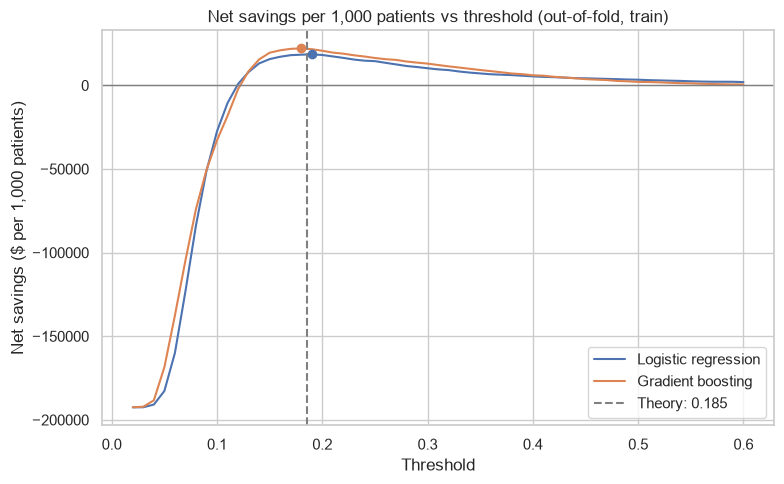

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for name, s in sweep.items():
    ax.plot(s["threshold"], s["savings_per_1000"], label=name)
    b = best[name]
    ax.scatter(b["threshold"], b["savings_per_1000"], zorder=3)
ax.axhline(0, color="grey", lw=1)
ax.axvline(C_FOLLOWUP / (EFFECT * C_READMIT), ls="--", color="grey", label="Theory: 0.185")
ax.set(title="Net savings per 1,000 patients vs threshold (out-of-fold, train)",
       xlabel="Threshold", ylabel="Net savings ($ per 1,000 patients)")
ax.legend()
plt.tight_layout()
plt.savefig(FIG / "04_savings_vs_threshold.png", dpi=150)
plt.show()

**Two sanity checks:**
- *Flag everyone* (threshold 0): we pay $500 for every patient but only ~11% would be readmitted, so we **lose** money.
- *Flag nobody* (threshold 1): $0. The model is only useful if some threshold beats $0.

In [6]:
for name, p in oof.items():
    everyone = evaluate(y_train, p, 0.0)["savings_per_1000"]
    print(f"{name}: flag everyone = ${everyone:,.0f} per 1,000 patients;  best threshold = ${best[name]['savings_per_1000']:,.0f}")

Logistic regression: flag everyone = $-192,499 per 1,000 patients;  best threshold = $18,531
Gradient boosting: flag everyone = $-192,499 per 1,000 patients;  best threshold = $22,098


## 5. Final result on the untouched test set
Apply each model's chosen threshold (picked on training data) to the test set, once.

In [7]:
final = pd.DataFrame([{"model": name, **evaluate(y_test, test_pred[name], best[name]["threshold"])}
                      for name in models])
final.round(3)

,model,threshold,flagged_pct,TP,FP,FN,TN,recall,precision,fpr,savings_per_1000
0,Logistic regression,0.19,0.094,508,1365,1755,16240,0.224,0.271,0.078,21899.537
1,Gradient boosting,0.18,0.123,626,1813,1637,15792,0.277,0.257,0.103,23691.363


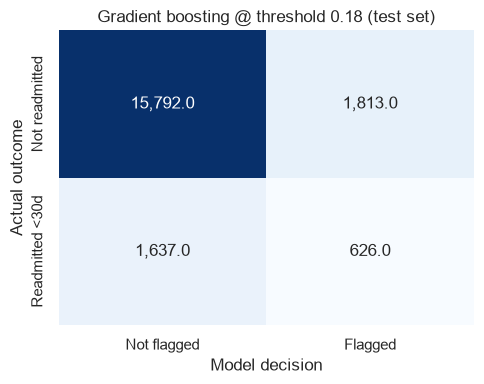

Chosen model: Gradient boosting
Flags 12.3% of patients, catches 27.7% of readmissions, precision 25.7% (vs base rate 11.4%)
Estimated net savings: $23,691 per 1,000 discharges


In [8]:
chosen = "Gradient boosting" if final.set_index("model").loc["Gradient boosting", "savings_per_1000"] >= \
                                final.set_index("model").loc["Logistic regression", "savings_per_1000"] else "Logistic regression"
row = final.set_index("model").loc[chosen]
cm = np.array([[row["TN"], row["FP"]], [row["FN"], row["TP"]]])

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["Not flagged", "Flagged"], yticklabels=["Not readmitted", "Readmitted <30d"])
ax.set(title=f"{chosen} @ threshold {row['threshold']:.2f} (test set)", xlabel="Model decision", ylabel="Actual outcome")
plt.tight_layout()
plt.savefig(FIG / "04_confusion_matrix.png", dpi=150)
plt.show()

print(f"Chosen model: {chosen}")
print(f"Flags {row['flagged_pct']:.1%} of patients, catches {row['recall']:.1%} of readmissions, "
      f"precision {row['precision']:.1%} (vs base rate {y_test.mean():.1%})")
print(f"Estimated net savings: ${row['savings_per_1000']:,.0f} per 1,000 discharges")

## 6. Sensitivity: how much do the assumptions matter?
Our dollar values are assumptions, so we re-run the threshold choice (on OOF training predictions) for a range of follow-up costs
and effectiveness levels, then score each on the test set. If the conclusion only holds for one lucky set of numbers, we should say so.

In [9]:
p_oof, p_test = oof[chosen], test_pred[chosen]
rows = []
for c_follow in [250, 500, 1000]:
    for effect in [0.10, 0.18, 0.30]:
        s = pd.DataFrame([evaluate(y_train, p_oof, t, c_follow=c_follow, effect=effect) for t in thresholds])
        t_best = s.loc[s["savings_per_1000"].idxmax(), "threshold"]
        r = evaluate(y_test, p_test, t_best, c_follow=c_follow, effect=effect)
        rows.append({"follow_up_cost": c_follow, "effect": effect, "threshold": t_best,
                     "flagged_pct": r["flagged_pct"], "recall": r["recall"], "precision": r["precision"],
                     "test_savings_per_1000": r["savings_per_1000"]})
sens = pd.DataFrame(rows)
sens.round(3)

,follow_up_cost,effect,threshold,flagged_pct,recall,precision,test_savings_per_1000
0,250,0.10,0.15,0.199,0.401,0.229,18698.410
1,250,0.18,0.09,0.566,0.768,0.155,94853.533
2,250,0.30,0.06,0.841,0.943,0.128,273354.137
3,500,0.10,0.33,0.016,0.066,0.464,3196.094
4,500,0.18,0.18,0.123,0.277,0.257,23691.363
5,500,0.30,0.12,0.349,0.576,0.188,120721.764
6,1000,0.10,0.60,0.001,0.003,0.500,-176.163
7,1000,0.18,0.36,0.011,0.050,0.502,4066.841
8,1000,0.30,0.22,0.060,0.173,0.326,28261.526


**How to read this table:**
- Cheaper or more effective follow-up -> lower threshold -> flag more patients (higher recall, lower precision).
- Expensive and weak follow-up ($1,000, 10%) -> the best threshold hits the top of our sweep (0.60) and savings are about zero or negative:
  the programme is **not worth running** under those assumptions. A threshold-by-cost method can tell you that, which an accuracy number never can.

## 7. Save the decision

In [10]:
decision = {
    "model": chosen,
    "model_file": "hgb.joblib" if chosen == "Gradient boosting" else "logreg.joblib",
    "threshold": float(row["threshold"]),
    "assumptions": {"C_READMIT": C_READMIT, "C_FOLLOWUP": C_FOLLOWUP, "EFFECT": EFFECT},
    "test": {k: float(row[k]) for k in ["flagged_pct", "recall", "precision", "fpr", "savings_per_1000"]},
}
(MODELS / "threshold.json").write_text(json.dumps(decision, indent=2))
print(json.dumps(decision, indent=2))

{
  "model": "Gradient boosting",
  "model_file": "hgb.joblib",
  "threshold": 0.18,
  "assumptions": {
    "C_READMIT": 15000,
    "C_FOLLOWUP": 500,
    "EFFECT": 0.18
  },
  "test": {
    "flagged_pct": 0.12276021743507147,
    "recall": 0.276623950508175,
    "precision": 0.2566625666256663,
    "fpr": 0.10298210735586481,
    "savings_per_1000": 23691.362995772095
  }
}


## 8. Limitation
The dollar figures are assumptions, and "18% of readmissions prevented" comes from trials of discharge
programmes in general, not from this hospital. The savings figure is an *illustration of the decision method*,
not a forecast.